# kNN neighborhood signals: can a training-free signal rank the error (paper format)

Draws the kNN counterpart of the axes figure. The cascade and the guards are those of `three_channels_analysis/canal_2/canal2_uncertainty_vs_error_classic.ipynb`.

Here the uncertainty does **not** come from the head: it comes from the neighborhood, and there are **two signals** instead of one. Color is the prediction head whose error is being ranked; the marker SHAPE is the signal; hollow versus filled is the control, as everywhere else.
The control entries deliberately show **both** marker shapes: hollow/filled is a property of the CONTROL and not of the signal, and drawing only the circle would suggest the convention applies to that signal alone.

In [1]:
import sys
import json
from pathlib import Path

import numpy as np
import pandas as pd
import yaml
import matplotlib.pyplot as plt

PROJ = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "src").is_dir())
sys.path.append(str(PROJ))
from src.evaluation.benchmark_summary import donor_lopo_stats

# =============================== SETTINGS ====================================
RUN_ID      = "pr_classic3"
RESULTS     = PROJ / "results"
DATASETS    = ["10x_TuPro", "TLS", "LUNG_CANCER"]
RADIUS      = "r75"
LAMBDA_KEEP = 0.0
MODELS = ["homoscedastic", "heteroscedastic", "spot_homoscedastic",
          "poisson_cp", "negativebinomial_hetero_noanchor_cp"]
PLOT_CASES = ["lin_all", "lin_pos", "log_pos"]   # one PDF per case, in this order
# lin_all is DRAWN here but does not read like the other two. At y = 0 the absolute
# error IS |mu|, so the NAIVE value tends to the uncertainty-mean coupling BY
# CONSTRUCTION, and the partial is ill-conditioned there (r_Dm -> 1). These panels
# DEMONSTRATE the confound; they do not measure it. The measurement is lin_pos.
FIGDIR = PROJ / "results" / "_analysis" / "figures_paper"
# =============================================================================

N_PLUS_MIN = 60
CONVENTION = "v3_native_scale"
AXES = ["gene", "spot"]
N_COL = {"lin_all": "n_plus_all", "lin_pos": "n_plus_pos", "log_pos": "n_plus_pos"}
CASE_FIG = {"lin_all": "|y - mu|, all (spot, gene) entries, zeros included",
            "lin_pos": "|y - mu|, detected entries only (y > 0)",
            "log_pos": "|log y - log mu|, detected entries only (y > 0)"}

# The two neighborhood signals, in the order they are STACKED under each model.
#   marker = the SIGNAL,  hollow/filled = uncontrolled / controlled.
# The grain predicts the degeneracy: a signal of grain 'spot' is constant within a group of
# the spot axis, hence mute on that axis and live on the gene axis.
KNN_SIGNALS = [
    # The distance NORMALIZED by the leiden cluster radius, not the raw distance: dividing by
    # the local scale removes the part that is 'far from its neighbors because this TYPE is
    # rare'. leiden is the only clustering available on all three cohorts.
    ("dist",  "canal2_knn_d_norm_leiden", "o", "spot", "kNN distance, normalized"),
    ("sigma", "canal2_knn_sigma_knn",     "s", "pair", "kNN local expression dispersion"),
]

MODEL_COLORS = {
    "homoscedastic":                        "#1f77b4",   # blue
    "heteroscedastic":                      "#ff7f0e",   # orange
    "spot_homoscedastic":                   "#2ca02c",   # green
    "poisson_cp":                           "#d62728",   # red
    "negativebinomial_hetero_noanchor_cp":  "#9467bd",   # violet
}
MODEL_LABELS = {
    "homoscedastic":                        "Gaussian gene-homoscedastic",
    "heteroscedastic":                      "Gaussian heteroscedastic",
    "spot_homoscedastic":                   "Gaussian spot-homoscedastic",
    "poisson_cp":                           "Poisson",
    "negativebinomial_hetero_noanchor_cp":  "Negative binomial",
}
DATASET_LABELS = {"10x_TuPro": "Tumor Profiler", "TLS": "Kidney/Lung with TLS",
                  "LUNG_CANCER": "NSCLC"}

DONOR_MAP = yaml.safe_load((PROJ / "snake" / "config" / "donor_slide_map.yaml").read_text())

def slide_to_donor(ds):
    m = DONOR_MAP.get(ds) or {}
    return {sl: d for d, slides in m.items() for sl in slides}


def canal_dir(ds, model, canal):
    """The canal2 directory of one (cohort, model, source), or None if missing or stale."""
    base = RESULTS / ds / RUN_ID / f"_{ds}_hvg_top3000" / RADIUS / model
    if not base.is_dir():
        return None
    for leaf in [base] + sorted(base.glob("lambda_*")):
        if leaf.name.startswith("lambda_"):
            if LAMBDA_KEEP is None or not np.isclose(float(leaf.name[len("lambda_"):]), LAMBDA_KEEP):
                continue
        d = leaf / canal
        if (d / "summary.json").is_file():
            s = json.loads((d / "summary.json").read_text())
            if s.get("not_applicable") or s.get("canal2_convention") != CONVENTION:
                return None
            return d
    return None


# The parquets, read ONCE each: the two error cases are then re-read from memory.
KFRAMES, kmiss = {}, []
for ds in DATASETS:
    for m in MODELS:
        for key, canal, _mk, _grain, _lab in KNN_SIGNALS:
            d = canal_dir(ds, m, canal)
            if d is None:
                kmiss.append((ds, m, key))
                continue
            for axis, fname in (("gene", "pair_partial.parquet"), ("spot", "spot_partial.parquet")):
                f = d / fname
                if f.is_file():
                    KFRAMES[(ds, m, key, axis)] = pd.read_parquet(f)

print(f"run {RUN_ID}   {len(KFRAMES)} parquet(s) read")
if kmiss:
    print(f"\n(!) {len(kmiss)} (cohort, model, signal) with no conforming precompute, DROPPED:")
    for ds, m, k in kmiss:
        print(f"    {ds:<12s} {m:<40s} {k}")

run pr_classic3   60 parquet(s) read


## 1. The donor cascade, for both error cases

Same cascade as everywhere in canal 2, computed once per `(cohort, head, signal, axis, case)` so that the figure cell only reads it back.

In [2]:
def donor_points(frame, ds, axis, case, stat):
    """{donor: value}. The n >= N_PLUS_MIN filter and the NaN removal happen HERE because the
    parquet carries EVERY group present."""
    col, ncol = f"{stat}_{case}", N_COL[case]
    if frame is None or col not in frame.columns or ncol not in frame.columns:
        return {}, 0
    d = frame[(frame[ncol] >= N_PLUS_MIN) & frame[col].notna()]
    if d.empty:
        return {}, 0
    s2d = slide_to_donor(ds)
    donor = d["slide"].map(lambda s: s2d.get(s, s))
    if axis == "spot":                       # one spot = one slide = one donor: plain mean
        return d.groupby(donor.to_numpy())[col].mean().to_dict(), int(len(d))
    g = pd.DataFrame({"gene": d["gene"].to_numpy(), "donor": donor.to_numpy(),
                      "w": d[col].to_numpy() * d[ncol].to_numpy(),
                      "n": d[ncol].to_numpy()}).groupby(["gene", "donor"], as_index=False).sum()
    g["v"] = g["w"] / g["n"]
    return g.groupby("donor")["v"].mean().to_dict(), int(len(d))


krows = []
for (ds, m, key, axis), frame in KFRAMES.items():
    for case in PLOT_CASES:
        rec = dict(dataset=ds, model=m, signal=key, axis=axis, case=case)
        for stat, tag in (("r_uD", "naive"), ("r_partial", "partial")):
            pts, n = donor_points(frame, ds, axis, case, stat)
            if not pts:
                continue
            st = donor_lopo_stats(pts)
            rec.update({tag: st["mean"], f"{tag}_lo": st["ci95_mean"][0],
                        f"{tag}_hi": st["ci95_mean"][1], "K": st["K"], "n_groups": n})
        krows.append(rec)
KRES = pd.DataFrame(krows)


def kget(ds, m, sig, axis, case):
    r = KRES[(KRES["dataset"] == ds) & (KRES["model"] == m) & (KRES["signal"] == sig)
             & (KRES["axis"] == axis) & (KRES["case"] == case)] if not KRES.empty else KRES
    return None if r.empty else r.iloc[0]


print(f"{len(KRES)} rows computed over {len(PLOT_CASES)} error cases")
# The degeneracy PREDICTED by the signal's grain, tested against the data rather than assumed:
# a signal of grain 'spot' is constant within a group of the spot axis, hence mute there and live
# on the gene axis.
print("\nWHERE IS THE PARTIAL DEFINED?   V = defined, . = mute, - = absent")
for key, _canal, _mk, grain, lab in KNN_SIGNALS:
    print(f"\n  [{lab}]  grain = {grain}  -> expected mute on axis {grain if grain != 'pair' else '(none)'}")
    for axis in AXES:
        marks = []
        for ds in DATASETS:
            r = kget(ds, MODELS[0], key, axis, PLOT_CASES[0])
            marks.append("-" if r is None
                         else ("V" if np.isfinite(r.get("partial", np.nan)) else "."))
        print(f"      axis {axis:<5s} " + "  ".join(f"{ds}:{x}" for ds, x in zip(DATASETS, marks)))

180 rows computed over 3 error cases

WHERE IS THE PARTIAL DEFINED?   V = defined, . = mute, - = absent

  [kNN distance, normalized]  grain = spot  -> expected mute on axis spot
      axis gene  10x_TuPro:V  TLS:V  LUNG_CANCER:V
      axis spot  10x_TuPro:.  TLS:.  LUNG_CANCER:.

  [kNN local expression dispersion]  grain = pair  -> expected mute on axis (none)
      axis gene  10x_TuPro:V  TLS:V  LUNG_CANCER:V
      axis spot  10x_TuPro:V  TLS:V  LUNG_CANCER:V


## 2. The paper figure — 2 axes x 3 cohorts, one PDF per error case

Two markers are stacked under each head, one per signal. Knobs: `COL_W`, `ROW_H`, `LEGEND_FS`, `LEGEND_GUTTER`, `BOTTOM_PAD`.

[lin_all] legend strip = 0.203 of the width


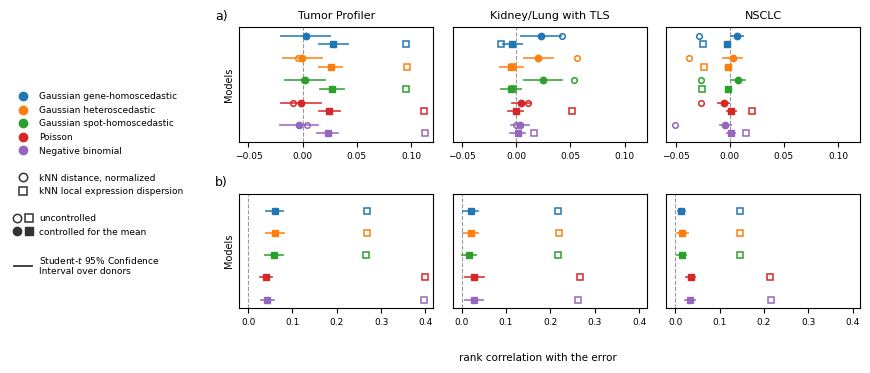

## FIGURE  fig_canal2_knn_paper_lin_all_pr_classic3.pdf
## TITLE   Can a training-free neighborhood signal rank a model's prediction error
## CAPTION Error definition: |y - mu|, all (spot, gene) entries, zeros included.
## CAPTION Colors are the prediction heads whose error is being ranked; the uncertainty itself
## CAPTION never comes from the head. Two markers are stacked under each head, one per signal:
## CAPTION o = kNN distance, normalized.
## CAPTION s = kNN local expression dispersion.
## CAPTION Hollow: no control. Filled: the partial correlation controlling for the predicted mean,
## CAPTION with a Student-t 95% interval over the 8 held-out donors.
## CAPTION a) grouping: one group per gene and slide, ranking the error across the spots of that gene.
## CAPTION b) grouping: one group per slide and spot, ranking the error across the genes of that spot.
## CAPTION The distance signal takes one value per spot, so it is constant inside a spot-level group
## CAPTION and can only ra

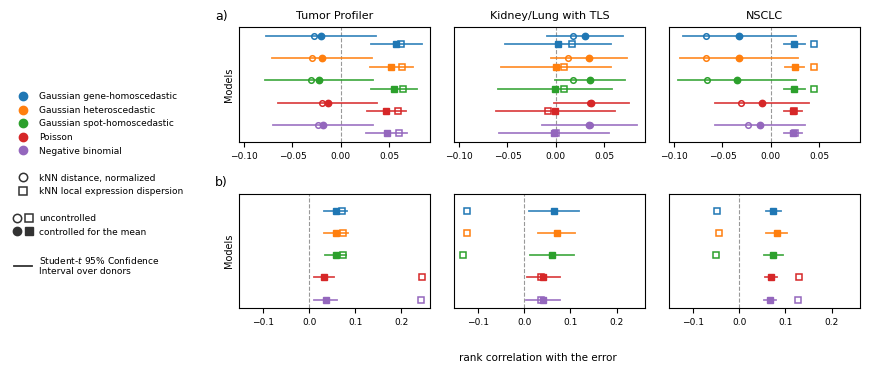

## FIGURE  fig_canal2_knn_paper_lin_pos_pr_classic3.pdf
## TITLE   Can a training-free neighborhood signal rank a model's prediction error
## CAPTION Error definition: |y - mu|, detected entries only (y > 0).
## CAPTION Colors are the prediction heads whose error is being ranked; the uncertainty itself
## CAPTION never comes from the head. Two markers are stacked under each head, one per signal:
## CAPTION o = kNN distance, normalized.
## CAPTION s = kNN local expression dispersion.
## CAPTION Hollow: no control. Filled: the partial correlation controlling for the predicted mean,
## CAPTION with a Student-t 95% interval over the 8 held-out donors.
## CAPTION a) grouping: one group per gene and slide, ranking the error across the spots of that gene.
## CAPTION b) grouping: one group per slide and spot, ranking the error across the genes of that spot.
## CAPTION The distance signal takes one value per spot, so it is constant inside a spot-level group
## CAPTION and can only rank spots: i

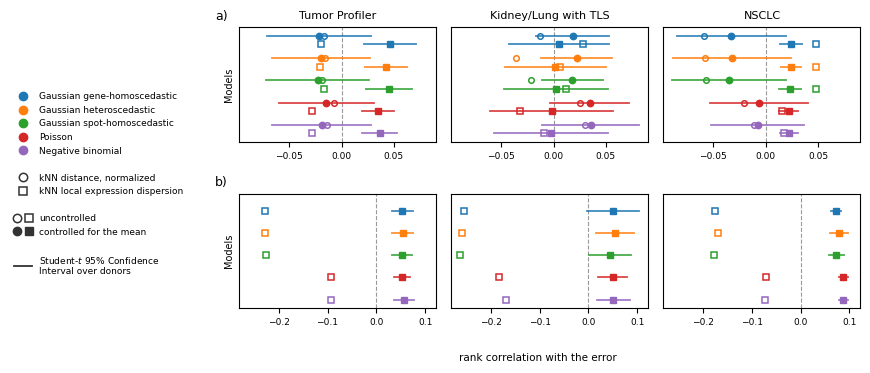

## FIGURE  fig_canal2_knn_paper_log_pos_pr_classic3.pdf
## TITLE   Can a training-free neighborhood signal rank a model's prediction error
## CAPTION Error definition: |log y - log mu|, detected entries only (y > 0).
## CAPTION Colors are the prediction heads whose error is being ranked; the uncertainty itself
## CAPTION never comes from the head. Two markers are stacked under each head, one per signal:
## CAPTION o = kNN distance, normalized.
## CAPTION s = kNN local expression dispersion.
## CAPTION Hollow: no control. Filled: the partial correlation controlling for the predicted mean,
## CAPTION with a Student-t 95% interval over the 8 held-out donors.
## CAPTION a) grouping: one group per gene and slide, ranking the error across the spots of that gene.
## CAPTION b) grouping: one group per slide and spot, ranking the error across the genes of that spot.
## CAPTION The distance signal takes one value per spot, so it is constant inside a spot-level group
## CAPTION and can only rank 

In [3]:
from matplotlib.lines import Line2D
from matplotlib.legend_handler import HandlerTuple

FIGDIR.mkdir(parents=True, exist_ok=True)


def fig_show(fig, stem, title, caption):
    """Save .pdf + .png, show, then PRINT the title and caption."""
    fig.savefig(f"{stem}.pdf", bbox_inches="tight")
    fig.savefig(f"{stem}.png", dpi=300, bbox_inches="tight")
    plt.show()
    print(f"## FIGURE  {stem.name}.pdf")
    print(f"## TITLE   {title}")
    for line in caption:
        print(f"## CAPTION {line}")


AXIS_GROUPING = {
    "gene": "one group per gene and slide, ranking the error across the spots of that gene",
    "spot": "one group per slide and spot, ranking the error across the genes of that spot",
}
NSIG, GAP, STEP = len(KNN_SIGNALS), 0.9, 2.4

COL_W         = 2.9     # width is the cheap axis: LaTeX places the figure at a fixed width
ROW_H         = 1.9     # compacted for the paper
LEGEND_FS     = 6.5
LEGEND_GUTTER = 0.02
BOTTOM_PAD    = 0.085

for case in PLOT_CASES:
    kdrawn = []
    fig, axes = plt.subplots(len(AXES), len(DATASETS),
                             figsize=(COL_W * len(DATASETS), ROW_H * len(AXES)),
                             sharex="row", squeeze=False)
    for i, axis in enumerate(AXES):
        for j, ds in enumerate(DATASETS):
            ax = axes[i, j]
            for k, m in enumerate(MODELS):
                c = MODEL_COLORS.get(m, "0.4")
                for t, (key, _canal, mk, _grain, _lab) in enumerate(KNN_SIGNALS):
                    y = k * STEP + t * GAP
                    r = kget(ds, m, key, axis, case)
                    if r is None:
                        continue
                    nv, pv = r.get("naive", np.nan), r.get("partial", np.nan)
                    if np.isfinite(nv):
                        ax.plot([nv], [y], mk, ms=4.0, mfc="none", mec=c, mew=1.1, zorder=3)
                    if not np.isfinite(pv):
                        kdrawn.append(dict(case=case, axis=axis, dataset=ds, model=m, signal=key,
                                           naive=nv, partial=np.nan, lo=np.nan, hi=np.nan))
                        continue
                    lo, hi = r.get("partial_lo", np.nan), r.get("partial_hi", np.nan)
                    if np.isfinite(lo):
                        ax.plot([lo, hi], [y, y], color=c, lw=1.3, alpha=0.85, zorder=3)
                    ax.plot([pv], [y], mk, ms=4.6, color=c, zorder=4)
                    kdrawn.append(dict(case=case, axis=axis, dataset=ds, model=m, signal=key,
                                       naive=nv, partial=pv, lo=lo, hi=hi))
            ax.axvline(0.0, color="0.6", lw=0.8, ls="--", zorder=1)
            ax.set_yticks([])
            if j == 0:
                ax.set_ylabel("Models", fontsize=7)
                ax.text(-0.06, 1.04, f"{'ab'[i]})", transform=ax.transAxes,
                        ha="right", va="bottom", fontsize=9)
            ax.set_ylim(-0.9, (len(MODELS) - 1) * STEP + (NSIG - 1) * GAP + 0.9)
            ax.invert_yaxis()
            ax.tick_params(axis="x", labelsize=6.5)
            if i == 0:
                ax.set_title(DATASET_LABELS.get(ds, ds), fontsize=8)
            # NO per-panel set_xlabel: three copies of the same text overlap.

    model_handles = [Line2D([], [], marker="o", ls="", color=MODEL_COLORS.get(m, "0.4"),
                            label=MODEL_LABELS.get(m, m)) for m in MODELS]
    sig_handles = [Line2D([], [], marker=mk, ls="", mfc="none", mec="#333333", mew=1.1, label=lab)
                   for _k, _c, mk, _g, lab in KNN_SIGNALS]
    # Each controlled/uncontrolled entry shows BOTH shapes: hollow/filled is a property of the
    # CONTROL and not of the signal, and showing only one would make the shape read as part of
    # the condition. HandlerTuple(ndivide=None) puts the shapes side by side in one box.
    cond_handles = [tuple(Line2D([], [], marker=mk, ls="", mfc="none", mec="#333333", mew=1.1)
                          for _k, _c, mk, _g, _l in KNN_SIGNALS),
                    tuple(Line2D([], [], marker=mk, ls="", color="#333333")
                          for _k, _c, mk, _g, _l in KNN_SIGNALS)]
    bar_handle = Line2D([], [], color="#333333", lw=1.3, marker="")
    sp1, sp2, sp3 = (Line2D([], [], ls="", marker="", label="") for _ in range(3))
    handles = (model_handles + [sp1] + sig_handles + [sp2] + cond_handles + [sp3] + [bar_handle])
    # A tuple handle carries no label, so as soon as there is one the labels are passed
    # explicitly for the WHOLE legend.
    labels = ([h.get_label() for h in model_handles] + [""]
              + [h.get_label() for h in sig_handles] + [""]
              + ["uncontrolled", "controlled for the mean"] + [""]
              + ["Student-$t$ 95% Confidence \nInterval over donors"])
    leg = fig.legend(handles=handles, labels=labels,
                     handler_map={tuple: HandlerTuple(ndivide=None, pad=0.6)},
                     loc="center left", bbox_to_anchor=(0.0, 0.5),
                     ncol=1, frameon=False, fontsize=LEGEND_FS)
    fig.canvas.draw()
    legend_w = leg.get_window_extent().width / fig.bbox.width
    left = legend_w + LEGEND_GUTTER
    fig.tight_layout(rect=(left, BOTTOM_PAD, 1, 1))
    fig.text((left + 1) / 2, BOTTOM_PAD / 2, "rank correlation with the error",
             ha="center", va="center", fontsize=7.5)
    print(f"[{case}] legend strip = {legend_w:.3f} of the width")

    caption = [
        f"Error definition: {CASE_FIG[case]}.",
        "Colors are the prediction heads whose error is being ranked; the uncertainty itself",
        "never comes from the head. Two markers are stacked under each head, one per signal:",
        *[f"{mk} = {lab}." for _k, _c, mk, _g, lab in KNN_SIGNALS],
        "Hollow: no control. Filled: the partial correlation controlling for the predicted mean,",
        f"with a Student-t 95% interval over the {int(KRES['K'].max())} held-out donors.",
        *[f"{'ab'[q]}) grouping: {AXIS_GROUPING[a]}." for q, a in enumerate(AXES)],
        "The distance signal takes one value per spot, so it is constant inside a spot-level group",
        "and can only rank spots: its absence from b) is a property of the signal.",
        "The neighborhood dispersion is undefined where a spot has fewer than five detected",
        "neighbors, so it is not scored on exactly the entries of the other rosters.",
    ]
    fig_show(fig, FIGDIR / f"fig_canal2_knn_paper_{case}_{RUN_ID}",
             "Can a training-free neighborhood signal rank a model's prediction error",
             caption)

    KD = pd.DataFrame(kdrawn)
    print("\n" + "=" * 118)
    print(f"THE PRINTED TWIN - case {case}, exactly the plotted values")
    print("=" * 118)
    for axis in AXES:
        sub = KD[KD["axis"] == axis] if not KD.empty else KD
        if sub.empty:
            continue
        print(f"\n[axis {axis}]")
        print(f"    {'cohort':<22s} {'head':<32s} {'signal':<7s} {'naive':>9s} "
              f"{'controlled':>9s} {'95% CI':>22s}")
        for _, r in sub.iterrows():
            ci = f"[{r['lo']:+.4f}, {r['hi']:+.4f}]" if np.isfinite(r["lo"]) else "n/a"
            nv = f"{r['naive']:+.4f}" if np.isfinite(r["naive"]) else "     n/a"
            pv = f"{r['partial']:+.4f}" if np.isfinite(r["partial"]) else "    mute"
            print(f"    {DATASET_LABELS.get(r['dataset'], r['dataset']):<22s} "
                  f"{MODEL_LABELS.get(r['model'], r['model']):<32s} {r['signal']:<7s} "
                  f"{nv:>9s} {pv:>9s} {ci:>22s}")